In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv(
    "../datasets/raw/graduate_admissions/Admission_Predict.csv"
)

df.columns = df.columns.str.strip()

df = df.drop(columns=["Serial No."])

X = df.drop(columns=["Chance of Admit"])
y = df["Chance of Admit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (320, 7)
Testing shape: (80, 7)


In [3]:
underfit_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1000000))
])

underfit_model.fit(X_train, y_train)

print("Underfitting model trained!")

Underfitting model trained!


In [4]:
good_model = Pipeline([
    ("poly", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

good_model.fit(X_train, y_train)

print("Good-fit model trained!")

Good-fit model trained!


In [5]:
overfit_model = Pipeline([
    ("poly", PolynomialFeatures(
        degree=4,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

overfit_model.fit(X_train, y_train)

print("Overfitting model trained!")

Overfitting model trained!


In [6]:
models = {
    "Underfitting (High Ridge Alpha)": underfit_model,
    "Good Fit (Polynomial Degree 2)": good_model,
    "Overfitting (Polynomial Degree 4)": overfit_model
}

results = []

for name, model in models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,

        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),

        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

fit_results = pd.DataFrame(results)

display(fit_results.round(5))

,Model,Train MSE,Test MSE,Train R2,Test R2
0,Underfitting (High Ridge Alpha),0.01885,0.02579,0.00236,0.00130
1,Good Fit (Polynomial Degree 2),0.00346,0.00451,0.81704,0.82538
2,Overfitting (Polynomial Degree 4),0.00021,0.87718,0.98898,-32.96851


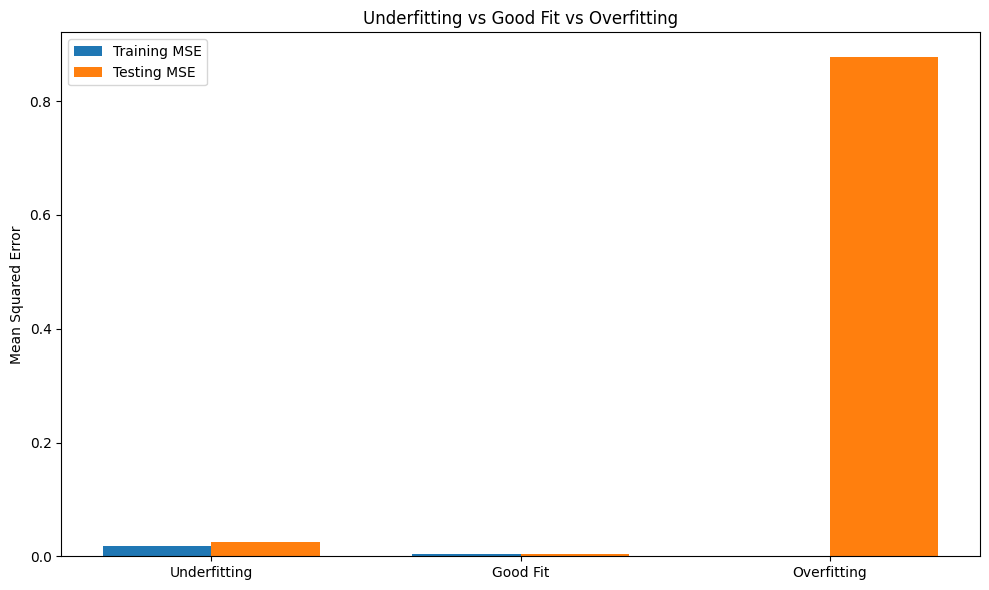

In [7]:
x = np.arange(len(fit_results))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    fit_results["Train MSE"],
    width,
    label="Training MSE"
)

plt.bar(
    x + width/2,
    fit_results["Test MSE"],
    width,
    label="Testing MSE"
)

plt.xticks(
    x,
    ["Underfitting", "Good Fit", "Overfitting"]
)

plt.ylabel("Mean Squared Error")
plt.title("Underfitting vs Good Fit vs Overfitting")
plt.legend()
plt.tight_layout()
plt.show()

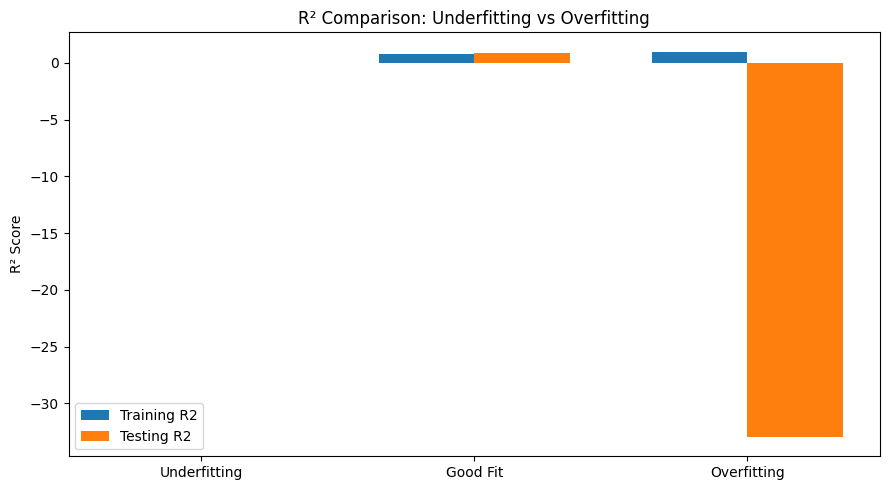

In [8]:
x = np.arange(len(fit_results))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    fit_results["Train R2"],
    width,
    label="Training R2"
)

plt.bar(
    x + width/2,
    fit_results["Test R2"],
    width,
    label="Testing R2"
)

plt.xticks(
    x,
    ["Underfitting", "Good Fit", "Overfitting"]
)

plt.ylabel("R² Score")
plt.title("R² Comparison: Underfitting vs Overfitting")
plt.legend()
plt.tight_layout()
plt.show()